Code to add to the raw dlc h5 data a new 'bodypart' named weigthed, which is the nose bodypart if its likelihood is greater than 0.3 and a weigted sum according to the likelihoods of all other bodyparts if it less than 0.3.
We then can define this bodypart in the NaviGraph to get less NaN values in the result (now we'll get Nan only for row where all values in DC where NaN)

In [47]:
import numpy as np
import pandas as pd
import pickle
import matplotlib.pyplot as plt


In [50]:
folder_path = "/var/home/almogmeir/Documents/M.Sc/Project/DLC/12NPM_03_12_25_2025_03_12_10_58_38/"
file_name = "12NPM_03_12_25_2025_03_12_10_58_38_cam1_masked_masked"

In [51]:
# Read the h5 file, update the path to the raw h5 DLC outputs
h5_file = pd.read_hdf(folder_path + file_name + ".h5")

In [52]:
h5_file

scorer    DLC_Resnet101_NeuroMazeMar26shuffle7_snapshot_170              \
bodyparts                                              nose               
coords                                                    x           y   
0                                                756.843933  299.617523   
1                                                756.654236  299.802704   
2                                                756.711975  299.768250   
3                                                756.631226  299.808075   
4                                                756.591675  299.753632   
...                                                     ...         ...   
143548                                           402.848206  500.646637   
143549                                           406.520355  500.555695   
143550                                           406.017792  499.977509   
143551                                           406.185211  499.723999   
143552                                           407.591217  499.202271   

scorer                                                               \
bodyparts                  ear_L                              ear_R   
coords    likelihood           x           y likelihood           x   
0           0.073495  780.751892  298.828644   0.048070  611.582214   
1           0.034636  602.294312  392.840576   0.041232  611.065674   
2           0.036971  602.258728  392.717773   0.043762  611.112732   
3           0.042562  602.249207  392.708344   0.043918  611.077209   
4           0.045068  602.241394  392.716858   0.042793  611.103577   
...              ...         ...         ...        ...         ...   
143548      0.359842  384.614349  504.085907   0.851182  399.772430   
143549      0.371795  386.174683  502.914703   0.921133  401.373199   
143550      0.377449  387.157715  502.406921   0.889601  402.979248   
143551      0.368511  387.514526  501.848663   0.881215  403.104706   
143552      0.369944  388.822815  501.114380   0.890683  403.783508   

scorer                                                               \
bodyparts                           mid_body                          
coords              y likelihood           x           y likelihood   
0          375.519958   0.050433  619.543518  629.243591   0.312723   
1          375.418640   0.051400  619.358032  629.393005   0.286362   
2          375.325256   0.051711  619.445312  629.366211   0.290038   
3          375.320557   0.051611  619.585693  629.394165   0.283633   
4          375.354492   0.051340  619.534546  629.362610   0.283085   
...               ...        ...         ...         ...        ...   
143548     519.413696   0.948341  377.968658  528.615173   0.777026   
143549     520.064453   0.970034  378.139984  527.228943   0.730640   
143550     518.644287   0.995152  377.747131  526.458923   0.737961   
143551     518.089050   0.987404  378.024933  525.804077   0.747717   
143552     517.417725   0.978107  379.252441  524.678040   0.755203   

scorer                                                                \
bodyparts   tail_base                         head_stage               
coords              x           y likelihood           x           y   
0          603.243347  385.173676   0.159543  772.452820  291.964691   
1          603.032471  385.009918   0.163226  612.610046  379.199768   
2          603.248535  384.902771   0.160776  612.706055  379.175629   
3          603.242859  384.837433   0.160210  765.137573  292.467529   
4          603.218872  384.853760   0.160272  765.158081  292.596069   
...               ...         ...        ...         ...         ...   
143548     358.231171  550.448425   0.518997  413.751221  495.419647   
143549     358.462250  549.893188   0.556386  415.009155  496.705444   
143550     358.447449  549.010315   0.596641  416.297424  495.659698   
143551     359.446472  548.162537   0.602228  416.460449  495.547760   
143552     361.054932  

In [53]:
# Update to be the actual file name according to the first index column value of the h5 table
file_name = 'DLC_Resnet101_NeuroMazeMar26shuffle7_snapshot_170'

# Load the DataFrame from the HDF5 file
dlc_raw_h5 = h5_file[file_name]

# Extract the MultiIndex from the first two rows
multi_index = pd.MultiIndex.from_arrays([dlc_raw_h5.iloc[0], dlc_raw_h5.iloc[1]])

# Convert the data to numeric, errors='coerce' will turn non-numeric values into NaN
dlc_raw_h5 = dlc_raw_h5.apply(pd.to_numeric, errors='coerce')

new_index = pd.MultiIndex.from_tuples([
        ('weighted', 'x'),
        ('weighted', 'y'),
        ('weighted', 'likelihood')
    ])

new_index_df = pd.DataFrame(np.nan, index=range(len(dlc_raw_h5)), columns=new_index)


# Concatenate the original DataFrame with the new columns DataFrame
# dlc_raw_h5 = pd.concat([dlc_raw_h5, new_columns], axis=1)

dlc_raw_h5 = pd.concat([dlc_raw_h5, new_index_df], axis=1)
dlc_raw_h5

nose                              ear_L                         \
                 x           y likelihood           x           y likelihood   
0       756.843933  299.617523   0.073495  780.751892  298.828644   0.048070   
1       756.654236  299.802704   0.034636  602.294312  392.840576   0.041232   
2       756.711975  299.768250   0.036971  602.258728  392.717773   0.043762   
3       756.631226  299.808075   0.042562  602.249207  392.708344   0.043918   
4       756.591675  299.753632   0.045068  602.241394  392.716858   0.042793   
...            ...         ...        ...         ...         ...        ...   
143548  402.848206  500.646637   0.359842  384.614349  504.085907   0.851182   
143549  406.520355  500.555695   0.371795  386.174683  502.914703   0.921133   
143550  406.017792  499.977509   0.377449  387.157715  502.406921   0.889601   
143551  406.185211  499.723999   0.368511  387.514526  501.848663   0.881215   
143552  407.591217  499.202271   0.369944  388.822815  501.114380   0.890683   

             ear_R                           mid_body  ...             \
                 x           y likelihood           x  ... likelihood   
0       611.582214  375.519958   0.050433  619.543518  ...   0.312723   
1       611.065674  375.418640   0.051400  619.358032  ...   0.286362   
2       611.112732  375.325256   0.051711  619.445312  ...   0.290038   
3       611.077209  375.320557   0.051611  619.585693  ...   0.283633   
4       611.103577  375.354492   0.051340  619.534546  ...   0.283085   
...            ...         ...        ...         ...  ...        ...   
143548  399.772430  519.413696   0.948341  377.968658  ...   0.777026   
143549  401.373199  520.064453   0.970034  378.139984  ...   0.730640   
143550  402.979248  518.644287   0.995152  377.747131  ...   0.737961   
143551  403.104706  518.089050   0.987404  378.024933  ...   0.747717   
143552  403.783508  517.417725   0.978107  379.252441  ...   0.755203   

         tail_base                         head_stage                         \
                 x           y likelihood           x           y likelihood   
0       603.243347  385.173676   0.159543  772.452820  291.964691   0.043453   
1       603.032471  385.009918   0.163226  612.610046  379.199768   0.029573   
2       603.248535  384.902771   0.160776  612.706055  379.175629   0.030001   
3       603.242859  384.837433   0.160210  765.137573  292.467529   0.029752   
4       603.218872  384.853760   0.160272  765.158081  292.596069   0.033168   
...            ...         ...        ...         ...         ...        ...   
143548  358.231171  550.448425   0.518997  413.751221  495.419647   0.791948   
143549  358.462250  549.893188   0.556386  415.009155  496.705444   0.866857   
143550  358.447449  549.010315   0.596641  416.297424  495.659698   0.880455   
143551  359.446472  548.162537   0.602228  416.460449  495.547760   0.860744   
143552  361.054932  547.293823   0.667698  415.893921  495.629761   0.826583   

       weighted                 
              x   y likelihood  
0           NaN NaN        NaN  
1           NaN NaN        NaN  
2           NaN NaN        NaN  
3           NaN NaN        NaN  
4           NaN NaN        NaN  
...         ...  ..        ...  
143548      NaN NaN        NaN  
143549      NaN NaN        NaN  
143550      NaN NaN        NaN  
143551      NaN NaN        NaN  
143552      NaN NaN        NaN  

[143553 rows x 21 columns]

In [ ]:
# def calculate_weighted_coordinates(row):
#     body_parts = ['ear_R', 'ear_L', 'mid_body', 'tail_base', 'head_stage']
#     total_weight = 0
#     weighted_x = 0
#     weighted_y = 0
#     weighted_likelihood = 0
#     likelihoods = []

#     for part in body_parts:
#         likelihood = row[part]['likelihood']
#         likelihoods.append(likelihood)
#         if likelihood > 0:
#             weighted_x += row[part]['x'] * likelihood
#             weighted_y += row[part]['y'] * likelihood
#             total_weight += likelihood

#     if total_weight > 0:
#         weighted_x /= total_weight
#         weighted_y /= total_weight
#         weighted_likelihood = sum([likelihood * (likelihood / total_weight) for likelihood in likelihoods])
#     likelihoods = []

#     return (weighted_x, weighted_y, weighted_likelihood)

# # # Apply the function to each row in the dataframe
# # dlc_raw_h5['weighted'][['x', 'y', 'likelihood']] = dlc_raw_h5.apply(
# #     lambda row: calculate_weighted_coordinates(row) if row['nose']['likelihood'] < 0.3 else pd.Series([row['nose']['x'], row['nose']['y'], row['nose']['likelihood']]),
# #     axis=1
# # )

# for i, row in enumerate(dlc_raw_h5.iterrows()):
#     if row[1]['nose']['likelihood'] >= 0.3:
#         dlc_raw_h5.loc[i, ('weighted', ['x', 'y', 'likelihood'])] = (row[1]['nose']['x'], row[1]['nose']['y'], row[1]['nose']['likelihood'])
#     else:
#         dlc_raw_h5.loc[i, ('weighted', ['x', 'y', 'likelihood'])] = calculate_weighted_coordinates(row[1])

# # Display the updated dataframe
# dlc_raw_h5


nose                               ear_L              \
                  x           y likelihood            x           y   
0       1297.983154  983.381165   0.431004  1301.035278  989.675110   
1       1297.806885  983.313232   0.439588  1300.918945  989.591187   
2       1297.884521  983.149963   0.440869  1300.909668  989.560181   
3       1297.929077  983.143921   0.439708  1300.972046  989.524048   
4       1298.071167  983.272278   0.433305  1301.043213  989.605774   
...             ...         ...        ...          ...         ...   
143548  1298.862549  985.579956   0.424271   386.129974  504.064331   
143549   410.521240  496.422302   0.458756   386.586365  503.284851   
143550  1298.880005  985.566162   0.425120   387.366455  502.538696   
143551  1298.762939  985.504517   0.430501   388.013794  501.874146   
143552  1298.861206  985.582581   0.424186   389.599060  501.076813   

                        ear_R                             mid_body  ...  \
       likelihood           x            y likelihood            x  ...   
0        0.289643   21.653118  1006.018494   0.296977  1226.836914  ...   
1        0.289184   21.494226  1005.729980   0.284459     4.938797  ...   
2        0.294290   21.547333  1005.828674   0.283248     4.950881  ...   
3        0.292058   21.547070  1005.827820   0.282394     4.946735  ...   
4        0.288232   21.660812  1006.043152   0.292009     4.816325  ...   
...           ...         ...          ...        ...          ...  ...   
143548   0.893327  401.267181   519.348633   0.942303   378.786194  ...   
143549   0.938769  402.240509   520.156433   0.969324   378.646454  ...   
143550   0.905918  403.342651   518.341431   0.981317   378.386292  ...   
143551   0.883200  403.840210   518.144714   0.982116   378.901367  ...   
143552   0.891525  404.555450   517.431152   0.972554   379.564880  ...   

                     tail_base                         head_stage              \
       likelihood            x           y likelihood           x           y   
0        0.244646  1212.028687   28.951492   0.418888    9.371573  982.402710   
1        0.229472  1211.572998   28.360371   0.425376    9.244394  982.424316   
2        0.225801  1211.583740   28.429068   0.426016    9.235188  982.434509   
3        0.224703  1211.598633   28.423143   0.423962    9.234289  982.404175   
4        0.214242  1211.569336   28.364849   0.421606    9.320097  982.334961   
...           ...          ...         ...        ...         ...         ...   
143548   0.772520   358.325134  550.428040   0.571847  414.531860  496.007355   
143549   0.743751   358.882996  549.892883   0.562917  414.725494  496.876526   
143550   0.709996   358.746521  548.639221   0.626313  416.623474  495.577667   
143551   0.719511   359.702393  548.057007   0.667162  417.021088  495.295380   
143552   0.758008   359.798431  546.451050   0.638189  417.027588  495.686829   

                      weighted                         
       likelihood            x           y likelihood  
0        0.681662  1297.983154  983.381165   0.431004  
1        0.679922  1297.806885  983.313232   0.439588  
2        0.674294  1297.884521  983.149963   0.440869  
3        0.672150  1297.929077  983.143921   0.439708  
4        0.674633  1298.071167  983.272278   0.433305  
...           ...          ...         ...        ...  
143548   0.848309  1298.862549  985.579956   0.424271  
143549   0.887016   410.521240  496.422302   0.458756  
143550   0.922607  1298.880005  985.566162   0.425120  
143551   0.883615  1298.762939  985.504517   0.430501  
143552   0.899303  1298.861206  985.582581   0.424186  

[143553 rows x 21 columns]

In [54]:
def set_likelihood_to_zero_outside_boundary(df, bodypart, x_min, x_max, y_min, y_max):
    """
    Sets the likelihood of a bodypart to 0 if its coordinates are outside the given boundary.

    Parameters:
    df (pd.DataFrame): The dataframe containing the bodypart data.
    bodypart (str): The bodypart to check.
    x_min (float): Minimum x-coordinate boundary.
    x_max (float): Maximum x-coordinate boundary.
    y_min (float): Minimum y-coordinate boundary.
    y_max (float): Maximum y-coordinate boundary.
    """
    outside_boundary = (df[(bodypart, 'x')] < x_min) | (df[(bodypart, 'x')] > x_max) | \
                       (df[(bodypart, 'y')] < y_min) | (df[(bodypart, 'y')] > y_max)
    df.loc[outside_boundary, (bodypart, 'likelihood')] = 0

In [55]:
for bodypart in ['ear_R', 'ear_L', 'mid_body', 'tail_base', 'nose', 'head_stage']:
    set_likelihood_to_zero_outside_boundary(dlc_raw_h5, bodypart, 90, 1170, 70, 930)

In [56]:
def calculate_weighted_coordinates(row):
    nose_likelihood = row['nose']['likelihood']
    head_stage_likelihood = row['head_stage']['likelihood']
    
    # If either nose or head_stage has a likelihood at least 0.3, pick the one with the higher likelihood.
    if nose_likelihood >= 0.3 or head_stage_likelihood >= 0.3:
        if nose_likelihood >= head_stage_likelihood:
            return (row['nose']['x'], row['nose']['y'], nose_likelihood)
        else:
            return (row['head_stage']['x'], row['head_stage']['y'], head_stage_likelihood)
    
    # Both nose and head_stage have low likelihood, so use weighted sum of all body parts.
    body_parts = ['ear_R', 'ear_L', 'mid_body', 'tail_base', 'head_stage']
    total_weight = 0
    weighted_x = 0
    weighted_y = 0
    likelihoods = []

    for part in body_parts:
        likelihood = row[part]['likelihood']
        likelihoods.append(likelihood)
        if likelihood > 0:
            weighted_x += row[part]['x'] * likelihood
            weighted_y += row[part]['y'] * likelihood
            total_weight += likelihood

    if total_weight > 0:
        weighted_x /= total_weight
        weighted_y /= total_weight
        weighted_likelihood = sum(likelihood * (likelihood / total_weight) for likelihood in likelihoods)
    else:
        weighted_likelihood = 0

    return (weighted_x, weighted_y, weighted_likelihood)

for i, row in enumerate(dlc_raw_h5.iterrows()):
    dlc_raw_h5.loc[i, ('weighted', ['x', 'y', 'likelihood'])] = calculate_weighted_coordinates(row[1])

# Display the updated dataframe
dlc_raw_h5

nose                              ear_L                         \
                 x           y likelihood           x           y likelihood   
0       756.843933  299.617523   0.073495  780.751892  298.828644   0.048070   
1       756.654236  299.802704   0.034636  602.294312  392.840576   0.041232   
2       756.711975  299.768250   0.036971  602.258728  392.717773   0.043762   
3       756.631226  299.808075   0.042562  602.249207  392.708344   0.043918   
4       756.591675  299.753632   0.045068  602.241394  392.716858   0.042793   
...            ...         ...        ...         ...         ...        ...   
143548  402.848206  500.646637   0.359842  384.614349  504.085907   0.851182   
143549  406.520355  500.555695   0.371795  386.174683  502.914703   0.921133   
143550  406.017792  499.977509   0.377449  387.157715  502.406921   0.889601   
143551  406.185211  499.723999   0.368511  387.514526  501.848663   0.881215   
143552  407.591217  499.202271   0.369944  388.822815  501.114380   0.890683   

             ear_R                           mid_body  ...             \
                 x           y likelihood           x  ... likelihood   
0       611.582214  375.519958   0.050433  619.543518  ...   0.312723   
1       611.065674  375.418640   0.051400  619.358032  ...   0.286362   
2       611.112732  375.325256   0.051711  619.445312  ...   0.290038   
3       611.077209  375.320557   0.051611  619.585693  ...   0.283633   
4       611.103577  375.354492   0.051340  619.534546  ...   0.283085   
...            ...         ...        ...         ...  ...        ...   
143548  399.772430  519.413696   0.948341  377.968658  ...   0.777026   
143549  401.373199  520.064453   0.970034  378.139984  ...   0.730640   
143550  402.979248  518.644287   0.995152  377.747131  ...   0.737961   
143551  403.104706  518.089050   0.987404  378.024933  ...   0.747717   
143552  403.783508  517.417725   0.978107  379.252441  ...   0.755203   

         tail_base                         head_stage                         \
                 x           y likelihood           x           y likelihood   
0       603.243347  385.173676   0.159543  772.452820  291.964691   0.043453   
1       603.032471  385.009918   0.163226  612.610046  379.199768   0.029573   
2       603.248535  384.902771   0.160776  612.706055  379.175629   0.030001   
3       603.242859  384.837433   0.160210  765.137573  292.467529   0.029752   
4       603.218872  384.853760   0.160272  765.158081  292.596069   0.033168   
...            ...         ...        ...         ...         ...        ...   
143548  358.231171  550.448425   0.518997  413.751221  495.419647   0.791948   
143549  358.462250  549.893188   0.556386  415.009155  496.705444   0.866857   
143550  358.447449  549.010315   0.596641  416.297424  495.659698   0.880455   
143551  359.446472  548.162537   0.602228  416.460449  495.547760   0.860744   
143552  361.054932  547.293823   0.667698  415.893921  495.629761   0.826583   

          weighted                         
                 x           y likelihood  
0       638.089840  495.294581   0.211637  
1       612.372789  506.802391   0.199133  
2       612.523013  507.373917   0.200351  
3       620.484744  501.631767   0.196078  
4       621.360819  500.519656   0.195198  
...            ...         ...        ...  
143548  413.751221  495.419647   0.791948  
143549  415.009155  496.705444   0.866857  
143550  416.297424  495.659698   0.880455  
143551  416.460449  495.547760   0.860744  
143552  415.893921  495.629761   0.826583  

[143553 rows x 21 columns]

In [59]:
dlc_raw_h5[dlc_raw_h5['head_stage']['likelihood'] < 0.3]

nose                              ear_L                         \
                 x           y likelihood           x           y likelihood   
0       756.843933  299.617523   0.073495  780.751892  298.828644   0.048070   
1       756.654236  299.802704   0.034636  602.294312  392.840576   0.041232   
2       756.711975  299.768250   0.036971  602.258728  392.717773   0.043762   
3       756.631226  299.808075   0.042562  602.249207  392.708344   0.043918   
4       756.591675  299.753632   0.045068  602.241394  392.716858   0.042793   
...            ...         ...        ...         ...         ...        ...   
143530  351.585022  591.809814   0.105978  347.259430  603.997253   0.321553   
143531  350.927368  589.145264   0.100243  347.073761  598.930176   0.210539   
143532  349.913086  576.321289   0.106542  346.493591  592.412537   0.331572   
143533  349.285126  572.252380   0.087002  346.611298  585.836731   0.245955   
143534  357.268982  626.628296   0.111485  347.741364  575.553223   0.187298   

             ear_R                           mid_body  ...             \
                 x           y likelihood           x  ... likelihood   
0       611.582214  375.519958   0.050433  619.543518  ...   0.312723   
1       611.065674  375.418640   0.051400  619.358032  ...   0.286362   
2       611.112732  375.325256   0.051711  619.445312  ...   0.290038   
3       611.077209  375.320557   0.051611  619.585693  ...   0.283633   
4       611.103577  375.354492   0.051340  619.534546  ...   0.283085   
...            ...         ...        ...         ...  ...        ...   
143530  361.073975  605.183838   0.187053  353.860413  ...   0.667649   
143531  360.562256  600.550537   0.099906  353.690613  ...   0.648325   
143532  358.639557  593.022644   0.167309  353.155334  ...   0.637561   
143533  358.571991  581.019470   0.100089  352.748535  ...   0.698012   
143534  352.570160  625.278198   0.150471  351.579559  ...   0.710322   

         tail_base                         head_stage                         \
                 x           y likelihood           x           y likelihood   
0       603.243347  385.173676   0.159543  772.452820  291.964691   0.043453   
1       603.032471  385.009918   0.163226  612.610046  379.199768   0.029573   
2       603.248535  384.902771   0.160776  612.706055  379.175629   0.030001   
3       603.242859  384.837433   0.160210  765.137573  292.467529   0.029752   
4       603.218872  384.853760   0.160272  765.158081  292.596069   0.033168   
...            ...         ...        ...         ...         ...        ...   
143530  356.861694  670.119568   0.703102  354.375244  581.985291   0.241081   
143531  357.718567  664.597961   0.547213  354.838806  580.468018   0.125557   
143532  357.161072  654.059326   0.762080  352.392670  569.415649   0.188825   
143533  356.070618  645.387695   0.723746  352.509857  566.098938   0.147831   
143534  354.166077  628.663879   0.505889  349.757812  552.931335   0.188303   

          weighted                         
                 x           y likelihood  
0       638.089840  495.294581   0.211637  
1       612.372789  506.802391   0.199133  
2       612.523013  507.373917   0.200351  
3       620.484744  501.631767   0.196078  
4       621.360819  500.519656   0.195198  
...            ...         ...        ...  
143530  354.549457  633.258321   0.536028  
143531  354.696854  631.496476   0.484107  
143532  353.930193  621.084560   0.556130  
143533  353.501517  616.188783   0.575995  
143534  351.806629  601.829053   0.489967  

[23028 rows x 21 columns]

In [60]:
# Restore the top level index (scorer) with the file name
h5_file = pd.concat({file_name: dlc_raw_h5}, axis=1)
# Restore the index column names
h5_file.columns.names = ['scorer', 'bodyparts', 'coords']
h5_file

scorer    DLC_Resnet101_NeuroMazeMar26shuffle7_snapshot_170              \
bodyparts                                              nose               
coords                                                    x           y   
0                                                756.843933  299.617523   
1                                                756.654236  299.802704   
2                                                756.711975  299.768250   
3                                                756.631226  299.808075   
4                                                756.591675  299.753632   
...                                                     ...         ...   
143548                                           402.848206  500.646637   
143549                                           406.520355  500.555695   
143550                                           406.017792  499.977509   
143551                                           406.185211  499.723999   
143552                                           407.591217  499.202271   

scorer                                                               \
bodyparts                  ear_L                              ear_R   
coords    likelihood           x           y likelihood           x   
0           0.073495  780.751892  298.828644   0.048070  611.582214   
1           0.034636  602.294312  392.840576   0.041232  611.065674   
2           0.036971  602.258728  392.717773   0.043762  611.112732   
3           0.042562  602.249207  392.708344   0.043918  611.077209   
4           0.045068  602.241394  392.716858   0.042793  611.103577   
...              ...         ...         ...        ...         ...   
143548      0.359842  384.614349  504.085907   0.851182  399.772430   
143549      0.371795  386.174683  502.914703   0.921133  401.373199   
143550      0.377449  387.157715  502.406921   0.889601  402.979248   
143551      0.368511  387.514526  501.848663   0.881215  403.104706   
143552      0.369944  388.822815  501.114380   0.890683  403.783508   

scorer                                        ...                         \
bodyparts                           mid_body  ...              tail_base   
coords              y likelihood           x  ... likelihood           x   
0          375.519958   0.050433  619.543518  ...   0.312723  603.243347   
1          375.418640   0.051400  619.358032  ...   0.286362  603.032471   
2          375.325256   0.051711  619.445312  ...   0.290038  603.248535   
3          375.320557   0.051611  619.585693  ...   0.283633  603.242859   
4          375.354492   0.051340  619.534546  ...   0.283085  603.218872   
...               ...        ...         ...  ...        ...         ...   
143548     519.413696   0.948341  377.968658  ...   0.777026  358.231171   
143549     520.064453   0.970034  378.139984  ...   0.730640  358.462250   
143550     518.644287   0.995152  377.747131  ...   0.737961  358.447449   
143551     518.089050   0.987404  378.024933  ...   0.747717  359.446472   
143552     517.417725   0.978107  379.252441  ...   0.755203  361.054932   

scorer                                                               \
bodyparts                         head_stage                          
coords              y likelihood           x           y likelihood   
0          385.173676   0.159543  772.452820  291.964691   0.043453   
1          385.009918   0.163226  612.610046  379.199768   0.029573   
2          384.902771   0.160776  612.706055  379.175629   0.030001   
3          384.837433   0.160210  765.137573  292.467529   0.029752   
4          384.853760   0.160272  765.158081  292.596069   0.033168   
...               ...        ...         ...         ...        ...   
143548     550.448425   0.518997  413.751221  495.419647   0.791948   
143549     549.893188   0.556386  415.009155  496.705444   0.866857   
143550     549.010315   0.596641  416.297424  495.659698   0.880455   
143551     548.162537   0.602228  416

In [61]:
# Save the updated DataFrame back to the HDF5 file, update path and name as wish
h5_file.to_hdf(folder_path + file_name + '_updated.h5', key=file_name, mode='w')

In [79]:
import numpy as np
import pandas as pd

# List of body parts to check (excluding the reference 'mid_body')
body_parts = ['ear_R', 'ear_L', 'head_stage', 'nose', 'tail_base']

# Container for rows that are considered outliers.
outlier_rows = []

for index, row in dlc_raw_h5.iterrows():
    # Use nose coordinates as the reference point.
    ref_x = row['mid_body']['x']
    ref_y = row['mid_body']['y']
    
    # Variable to hold the outlier body part (if any)
    outlier_body = None
    
    # Check each body part
    for part in body_parts:
        dx = row[part]['x'] - ref_x
        dy = row[part]['y'] - ref_y
        distance = np.sqrt(dx**2 + dy**2)
        if distance > 300:
            outlier_body = part
            break
            
    if outlier_body:
        # Make a copy of the row and add the outlier body part information.
        new_row = row.copy()
        new_row['outlier_body'] = outlier_body
        outlier_rows.append(new_row)

outliers_df = pd.DataFrame(outlier_rows)
print("Found", len(outliers_df), "outlier rows.")

Found 6195 outlier rows.


In [80]:
outliers_df

nose                              ear_L                         \
                 x           y likelihood           x           y likelihood   
0       756.843933  299.617523   0.073495  780.751892  298.828644   0.048070   
1       756.654236  299.802704   0.034636  602.294312  392.840576   0.041232   
2       756.711975  299.768250   0.036971  602.258728  392.717773   0.043762   
3       756.631226  299.808075   0.042562  602.249207  392.708344   0.043918   
4       756.591675  299.753632   0.045068  602.241394  392.716858   0.042793   
...            ...         ...        ...         ...         ...        ...   
143034  359.162445  749.262878   0.163428  300.326813  773.977783   0.653291   
143089  168.660431  652.195984   0.112829  167.498581  663.736267   0.204188   
143090  168.865021  651.925232   0.105001  167.371872  663.211365   0.194436   
143441  173.207062  722.703430   0.191100  191.577560  707.654785   0.710564   
143442  173.485626  722.643311   0.186276  192.364517  707.145325   0.701143   

             ear_R                           mid_body  ...   tail_base  \
                 x           y likelihood           x  ...           x   
0       611.582214  375.519958   0.050433  619.543518  ...  603.243347   
1       611.065674  375.418640   0.051400  619.358032  ...  603.032471   
2       611.112732  375.325256   0.051711  619.445312  ...  603.248535   
3       611.077209  375.320557   0.051611  619.585693  ...  603.242859   
4       611.103577  375.354492   0.051340  619.534546  ...  603.218872   
...            ...         ...        ...         ...  ...         ...   
143034  302.620697  754.227661   0.662161  329.090942  ...  603.133057   
143089  635.057129  610.984009   0.059443  191.795959  ...  212.843796   
143090  635.038635  610.981934   0.060707  191.571594  ...  212.505905   
143441  173.924942  702.292480   0.574568  185.516907  ...  603.210327   
143442  175.197144  702.536438   0.584495  184.035492  ...  603.213623   

                               head_stage                           weighted  \
                 y likelihood           x           y likelihood           x   
0       385.173676   0.159543  772.452820  291.964691   0.043453  638.089840   
1       385.009918   0.163226  612.610046  379.199768   0.029573  612.372789   
2       384.902771   0.160776  612.706055  379.175629   0.030001  612.523013   
3       384.837433   0.160210  765.137573  292.467529   0.029752  620.484744   
4       384.853760   0.160272  765.158081  292.596069   0.033168  621.360819   
...            ...        ...         ...         ...        ...         ...   
143034  384.753113   0.155509  268.311646  772.939575   0.752677  268.311646   
143089  692.910339   1.000000  168.522476  659.787659   0.184816  207.370732   
143090  692.622498   1.000000  168.459900  659.504578   0.167999  207.776995   
143441  384.400360   0.161261  172.704803  715.463928   0.471783  172.704803   
143442  384.402893   0.161290  173.953430  713.233765   0.473101  173.953430   

                              outlier_body  
                 y likelihood               
0       495.294581   0.211637        ear_L  
1       506.802391   0.199133         nose  
2       507.373917   0.200351         nose  
3       501.631767   0.196078   head_stage  
4       500.519656   0.195198   head_stage  
...            ...        ...          ...  
143034  772.939575   0.752677    tail_base  
143089  679.288935   0.849266        ear_R  
143090  679.138942   0.854145        ear_R  
143441  715.463928   0.471783    tail_base  
143442  713.233765   0.473101    tail_base  

[6195 rows x 22 columns]

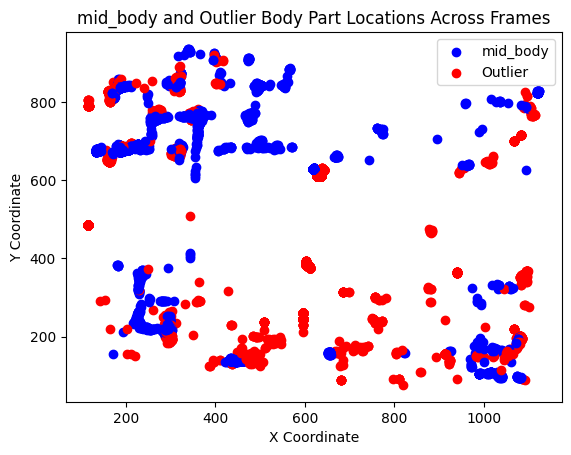

In [81]:
import matplotlib.pyplot as plt

# Iterate through each row in the outliers_df
for index, row in outliers_df.iterrows():
    # Extract the nose and outlier body part coordinates
    nose_x, nose_y = row['mid_body']['x'], row['mid_body']['y']
    outlier_body = row['outlier_body'].to_string().replace(' ', '')
    outlier_x, outlier_y = row[outlier_body]['x'], row[outlier_body]['y']
    
    # Plot the nose and outlier body part
    plt.scatter(nose_x, nose_y, color='blue', label='mid_body' if index == 0 else "")
    plt.scatter(outlier_x, outlier_y, color='red', label='Outlier' if index == 0 else "")

# Add labels and legend
plt.xlabel('X Coordinate')
plt.ylabel('Y Coordinate')
plt.title('mid_body and Outlier Body Part Locations Across Frames')
plt.legend()
plt.show()